<a href="https://colab.research.google.com/github/SrustiUB/Data-Science/blob/main/Copy_of_Trend_continuation_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 349.7/349.7 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.1/90.1 kB 2.1 MB/s eta 0:00:00
Dataset: (4053, 11)
Continuation Rate: 51.2 %
[flaml.automl.logger: 09-16 02:31:44] {2375} INFO - task = classification
[flaml.automl.logger: 09-16 02:31:44] {2386} INFO - Evaluation method: holdout
[flaml.automl.logger: 09-16 02:31:44] {2489} INFO - Minimizing error metric: log_loss
[flaml.automl.logger: 09-16 02:31:44] {2606} INFO - List of ML learners in AutoML Run: ['lgbm', 'rf', 'xgboost', 'extra_tree', 'xgb_limitdepth', 'sgd', 'lrl1']
[flaml.automl.logger: 09-16 02:31:44] {2911} INFO - iteration 0, current learner lgbm
[flaml.automl.logger: 09-16 02:31:44] {3046} INFO - Estimated sufficient time budget=1012s. Estimated necessary time budget=23s.
[flaml.automl.logger: 09-16 02:31:44] {3097} INFO -  at 0.1s,	estimator lgbm's best error=6.8299e-01,	best estimator lgbm's best error=6.8299e-01
[flaml.automl.logger: 09-16 02:31:44

INFO:flaml.tune.searcher.blendsearch:No low-cost partial config given to the search algorithm. For cost-frugal search, consider providing low-cost values for cost-related hps via 'low_cost_partial_config'. More info can be found at https://microsoft.github.io/FLAML/docs/FAQ#about-low_cost_partial_config-in-tune


[flaml.automl.logger: 09-16 02:31:45] {3097} INFO -  at 0.6s,	estimator sgd's best error=6.8608e-01,	best estimator lgbm's best error=6.6061e-01
[flaml.automl.logger: 09-16 02:31:45] {2911} INFO - iteration 16, current learner lgbm
[flaml.automl.logger: 09-16 02:31:45] {3097} INFO -  at 0.7s,	estimator lgbm's best error=6.3043e-01,	best estimator lgbm's best error=6.3043e-01
[flaml.automl.logger: 09-16 02:31:45] {2911} INFO - iteration 17, current learner sgd
[flaml.automl.logger: 09-16 02:31:45] {3097} INFO -  at 0.7s,	estimator sgd's best error=6.8608e-01,	best estimator lgbm's best error=6.3043e-01
[flaml.automl.logger: 09-16 02:31:45] {2911} INFO - iteration 18, current learner sgd
[flaml.automl.logger: 09-16 02:31:45] {3097} INFO -  at 0.7s,	estimator sgd's best error=6.7821e-01,	best estimator lgbm's best error=6.3043e-01
[flaml.automl.logger: 09-16 02:31:45] {2911} INFO - iteration 19, current learner xgboost
[flaml.automl.logger: 09-16 02:31:45] {3097} INFO -  at 0.8s,	estimato

INFO:flaml.tune.searcher.blendsearch:No low-cost partial config given to the search algorithm. For cost-frugal search, consider providing low-cost values for cost-related hps via 'low_cost_partial_config'. More info can be found at https://microsoft.github.io/FLAML/docs/FAQ#about-low_cost_partial_config-in-tune


[flaml.automl.logger: 09-16 02:32:41] {3097} INFO -  at 57.0s,	estimator lrl1's best error=6.8175e-01,	best estimator lgbm's best error=5.8110e-01
[flaml.automl.logger: 09-16 02:32:41] {2911} INFO - iteration 162, current learner lrl1
[flaml.automl.logger: 09-16 02:32:41] {3097} INFO -  at 57.0s,	estimator lrl1's best error=6.8107e-01,	best estimator lgbm's best error=5.8110e-01
[flaml.automl.logger: 09-16 02:32:41] {2911} INFO - iteration 163, current learner xgboost
[flaml.automl.logger: 09-16 02:32:41] {3097} INFO -  at 57.1s,	estimator xgboost's best error=6.4859e-01,	best estimator lgbm's best error=5.8110e-01
[flaml.automl.logger: 09-16 02:32:41] {2911} INFO - iteration 164, current learner xgb_limitdepth
[flaml.automl.logger: 09-16 02:32:41] {3097} INFO -  at 57.2s,	estimator xgb_limitdepth's best error=6.3356e-01,	best estimator lgbm's best error=5.8110e-01
[flaml.automl.logger: 09-16 02:32:41] {2911} INFO - iteration 165, current learner lrl1
[flaml.automl.logger: 09-16 02:32:

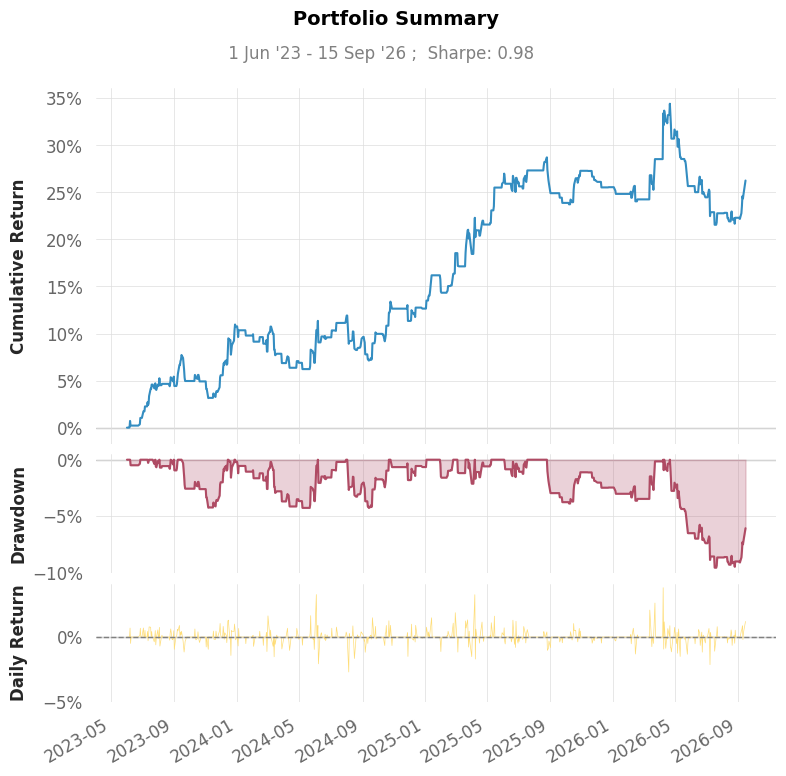

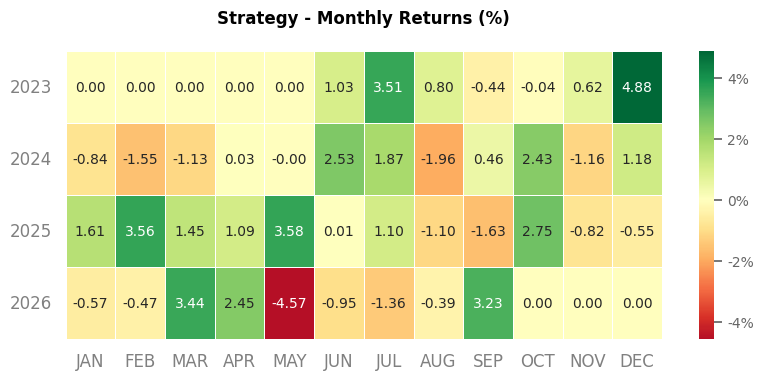


Latest Trend-Continuation Probability: 29.2 %
Current 10D Trend: Bearish


In [ ]:
# ============================================================
# NIFTY TREND-CONTINUATION PROBABILITY
# AutoML + QuantStats
# ============================================================

!pip -q install yfinance flaml quantstats

import yfinance as yf
import pandas as pd
import numpy as np
import quantstats as qs
from flaml import AutoML
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss

# 1. DATA
df = yf.download(
    "^NSEI",
    start="2010-01-01",
    auto_adjust=False,
    progress=False
)

if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

df = df[["Open","High","Low","Close","Volume"]].copy()
df["Return"] = df["Close"].pct_change()

# 2. FEATURES
df["SMA10"] = df["Close"].rolling(10).mean()
df["SMA20"] = df["Close"].rolling(20).mean()
df["SMA50"] = df["Close"].rolling(50).mean()

df["Trend10"] = df["Close"] / df["SMA10"] - 1
df["Trend20"] = df["Close"] / df["SMA20"] - 1
df["Trend50"] = df["Close"] / df["SMA50"] - 1

for n in [1, 5, 10, 20]:
    df[f"Ret_{n}"] = df["Close"].pct_change(n)

for n in [5, 10, 20]:
    df[f"Vol_{n}"] = df["Return"].rolling(n).std()

df["Range"] = (
    df["High"] - df["Low"]
) / df["Close"]

# 3. TARGET
# Trend continuation = next 10-day return
# has the same direction as current 10-day trend

future_return = (
    df["Close"].shift(-10) /
    df["Close"] - 1
)

df["Target"] = (
    np.sign(future_return) ==
    np.sign(df["Ret_10"])
).astype(int)

features = [
    "Trend10","Trend20","Trend50",
    "Ret_1","Ret_5","Ret_10","Ret_20",
    "Vol_5","Vol_10","Vol_20",
    "Range"
]

df = df.dropna(subset=features + ["Target"])

X = df[features]
y = df["Target"]

print("Dataset:", X.shape)
print("Continuation Rate:",
      round(y.mean()*100,2), "%")

# 4. TIME SPLIT
split = int(len(df)*0.80)

X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

# 5. AUTOML
automl = AutoML()

automl.fit(
    X_train,
    y_train,
    task="classification",
    metric="log_loss",
    time_budget=60,
    seed=42,
    eval_method="holdout"
)

print("\nBest Model:")
print(automl.model)

# 6. PROBABILITY
prob = automl.predict_proba(X_test)[:,1]

print("\nProbability Metrics")
print("-------------------")
print("ROC-AUC:",
      round(roc_auc_score(y_test,prob),4))
print("Log Loss:",
      round(log_loss(y_test,prob),4))
print("Brier:",
      round(brier_score_loss(y_test,prob),4))

# 7. PROBABILITY-BASED TREND STRATEGY
test = df.iloc[split:].copy()
test["Probability"] = prob

test["Position"] = np.where(
    (test["Probability"] >= 0.60) &
    (test["Ret_10"] > 0),
    1,
    np.where(
        (test["Probability"] >= 0.60) &
        (test["Ret_10"] < 0),
        -1,
        0
    )
)

test["Position"] = test["Position"].shift(1).fillna(0)

test["Strategy_Return"] = (
    test["Position"] * test["Return"]
)

# 8. QUANTSTATS
strategy = test["Strategy_Return"]

print("\nQuantStats")
print("----------")
print("Sharpe:",
      round(qs.stats.sharpe(strategy),3))

print("CAGR:",
      round(qs.stats.cagr(strategy)*100,2),"%")

print("Max Drawdown:",
      round(qs.stats.max_drawdown(strategy)*100,2),"%")

print("Volatility:",
      round(qs.stats.volatility(strategy)*100,2),"%")

qs.reports.basic(strategy)

# 9. CURRENT PROBABILITY
print("\nLatest Trend-Continuation Probability:",
      round(prob[-1]*100,2), "%")

print("Current 10D Trend:",
      "Bullish" if test["Ret_10"].iloc[-1] > 0 else "Bearish")